# Homework 1: Supervised vs. Self-Supervised Visual Representations

**Vessel classification on SeaShips crops: fine-tuned ResNet18 vs. frozen DINOv3 + linear probe**

**Author:** David N. Belyn
**Random seed:** 7399
**Environment:** Environment: run locally in VS Code (Jupyter), Windows, Python 3.13.6, CPU only (no GPU)

This notebook takes one labeled image-classification dataset, builds one leakage-aware train/validation/test split, and runs two very different approaches through it: a supervised ResNet18 adapted to the task, and a self-supervised DINOv3 encoder that never sees a single label and is only read out by a linear classifier. Both are scored on the exact same untouched test images.

## 1. Problem and Dataset

**Problem.** Given a single image of one vessel, classify it into one of six ship types. This is a classification problem, not detection: each image contains one vessel and gets one label.

**Why this dataset.** I built the midterm detector on SeaShips, and reusing it here is deliberate rather than lazy. Here the question shifts from "where are the ships and what are they" to "how much of the ship-type information lives in a general-purpose visual representation versus one tuned on these labels." The midterm also gave me a concrete reason to care about the answer: the cargo-type classes were the ones the detector confused most, so I want to see whether a self-supervised representation separates them better or worse.

**Source.** SeaShips (Shao, Z., Wu, W., Wang, Z., Du, W., & Li, C., 2018, "SeaShips: A large-scale precisely annotated dataset for ship detection," *IEEE Transactions on Multimedia*, 20(10), 2593-2604), accessed through the Hugging Face mirror `dronefreak/SeaShips`. The original images are 1920x1080 frames from coastal surveillance video.

**How the detection dataset becomes a classification dataset.** Every annotated bounding box becomes one classification image. I crop a square around each box (the box's longer side plus 15% context on each axis), so a long, low cargo ship is not squashed or chopped, and resize every crop to 320x320. A frame with three ships produces three classification images, which matters for leakage (Section 3).

**Classes (6).** 0 ore carrier, 1 bulk cargo carrier, 2 general cargo ship, 3 container ship, 4 fishing boat, 5 passenger ship.

The cells below download a random subsample of frames, extract the crops, and record everything in one manifest table that drives both models.

In [2]:
# Install dependencies. DINOv3 support needs a recent transformers release.
%pip install -U torch torchvision "transformers>=4.56" huggingface_hub imagehash scikit-learn pandas matplotlib pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import random
import time
import json
import copy
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

# ---- Reproducibility -------------------------------------------------
SEED = 7399
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

Using device: cpu


### Storage and access notes

I ran this notebook locally in VS Code on Windows, so `WORK_DIR` is a regular folder next to the notebook and the downloaded frames stay on disk between sessions. The download cell skips anything already there, which is why later runs report every frame as already on disk.

If you run it in Colab instead, anything under `/content/` disappears when the runtime disconnects. The download cell is resumable within one session, and setting `USE_DRIVE = True` keeps the frames in Google Drive across sessions.

DINOv3 weights on Hugging Face are gated. Before Section 6, request access on the model page while logged in to Hugging Face, and create a read token. The `login()` call at the top of Section 6 prompts for that token the first time; after that it is saved locally. In Colab, adding the token as an `HF_TOKEN` secret (key icon on the left) works too.

In [4]:
USE_DRIVE = False

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path("/content/drive/MyDrive/seaships_hw1")
else:
    WORK_DIR = Path("seaships_hw1")

FRAME_DIR = WORK_DIR / "frames"
CROP_DIR = WORK_DIR / "crops"
META_DIR = WORK_DIR / "metadata"
for d in [FRAME_DIR, CROP_DIR, META_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print("WORK_DIR:", WORK_DIR.resolve())

WORK_DIR: C:\Users\dbely\Downloads\seaships_hw1


In [5]:
# ---- Download SeaShips metadata over plain HTTP (same approach as the midterm) ----
# Each split folder on the mirror holds raw .jpg files plus a metadata.jsonl whose
# boxes are absolute-pixel COCO-style [x_min, y_min, width, height].
import urllib.request
import urllib.error

CLASS_NAMES = [
    "ore_carrier",
    "bulk_cargo_carrier",
    "general_cargo_ship",
    "container_ship",
    "fishing_boat",
    "passenger_ship",
]
NUM_CLASSES = len(CLASS_NAMES)

HF_SPLIT_DIRS = ["train", "valid", "test"]
HF_BASE_URL = "https://huggingface.co/datasets/dronefreak/SeaShips/resolve/main/data/images"

def hf_get(url_path, dest_path, max_retries=8, base_delay=2.0):
    # Retries with exponential backoff on HTTP 429 and transient server errors.
    dest_path.parent.mkdir(parents=True, exist_ok=True)
    url = f"{HF_BASE_URL}/{url_path}"
    for attempt in range(max_retries):
        try:
            urllib.request.urlretrieve(url, dest_path)
            return dest_path
        except (urllib.error.HTTPError, urllib.error.URLError) as e:
            is_last = attempt == max_retries - 1
            retryable = isinstance(e, urllib.error.URLError) and not isinstance(e, urllib.error.HTTPError)
            retryable = retryable or getattr(e, "code", None) in (429, 500, 502, 503, 504)
            if is_last or not retryable:
                raise
            wait = base_delay * (2 ** attempt)
            retry_after = getattr(e, "headers", None) and e.headers.get("Retry-After")
            if retry_after:
                try:
                    wait = max(wait, float(retry_after))
                except ValueError:
                    pass
            print(f"  {getattr(e, 'code', 'connection error')} on {url_path}, waiting {wait:.1f}s...")
            time.sleep(wait)
    raise RuntimeError(f"Failed to download {url}")

all_records = []
for split_dir in HF_SPLIT_DIRS:
    local_meta = META_DIR / f"{split_dir}_metadata.jsonl"
    if not local_meta.exists():
        hf_get(f"{split_dir}/metadata.jsonl", local_meta)
    with open(local_meta) as f:
        for line in f:
            rec = json.loads(line)
            rec["_split_dir"] = split_dir
            all_records.append(rec)

print("Frames available across all upstream splits:", len(all_records))

Frames available across all upstream splits: 7000


In [6]:
# ---- Download a random subsample of full frames (resumable) -----------------
# The upstream train/valid/test folders are pooled; this notebook builds its own
# leakage-aware split in Section 3.
N_FRAMES = 2500          # raise for more data if you have the time
REQUEST_PAUSE = 0.15     # seconds between downloads, to stay under HF's rate limit

frame_rng = random.Random(SEED)
frame_records = frame_rng.sample(all_records, min(N_FRAMES, len(all_records)))

n_skipped = 0
for i, rec in enumerate(frame_records):
    rec["frame_id"] = f"frame_{i:05d}"
    dest = FRAME_DIR / f"{rec['frame_id']}.jpg"
    if dest.exists():
        n_skipped += 1
        continue
    tmp = FRAME_DIR / f"_tmp_{rec['frame_id']}.jpg"
    hf_get(f"{rec['_split_dir']}/{rec['file_name']}", tmp)
    tmp.rename(dest)
    time.sleep(REQUEST_PAUSE)
    if (i + 1) % 250 == 0:
        print(f"Processed {i + 1}/{len(frame_records)} frames ({n_skipped} already on disk)...")

print(f"{len(frame_records)} frames ready ({n_skipped} were already on disk)")

2500 frames ready (2500 were already on disk)


In [7]:
# ---- Turn every bounding box into one square classification crop ------------
CROP_SIZE = 320       # saved crop size; models resize further in Section 4
CONTEXT_PAD = 0.15    # extra context around the box's longer side
MIN_LONG_SIDE = 32    # skip vessels too small to classify meaningfully

rows = []
n_tiny = 0
for rec in frame_records:
    with Image.open(FRAME_DIR / f"{rec['frame_id']}.jpg") as im:
        im = im.convert("RGB")
        frame_w, frame_h = im.size
        for k, ((x, y, w, h), cls_id) in enumerate(zip(rec["objects"]["bbox"], rec["objects"]["categories"])):
            if max(w, h) < MIN_LONG_SIDE:
                n_tiny += 1
                continue
            side = max(w, h) * (1 + CONTEXT_PAD)
            cx, cy = x + w / 2, y + h / 2
            left, top = round(cx - side / 2), round(cy - side / 2)
            # PIL fills any part of the square that falls outside the frame with black
            crop = im.crop((left, top, left + round(side), top + round(side)))
            crop = crop.resize((CROP_SIZE, CROP_SIZE), Image.BICUBIC)
            crop_id = f"{rec['frame_id']}_{k}"
            path = CROP_DIR / f"{crop_id}.jpg"
            crop.save(path, quality=95)
            rows.append(dict(crop_id=crop_id, frame_id=rec["frame_id"], path=str(path),
                             label=int(cls_id), class_name=CLASS_NAMES[int(cls_id)],
                             box_x=x, box_y=y, box_w=w, box_h=h,
                             frame_w=frame_w, frame_h=frame_h))

crops = pd.DataFrame(rows)
print(f"{len(crops)} classification images extracted from {crops.frame_id.nunique()} frames")
print(f"{n_tiny} boxes skipped as too small (longer side < {MIN_LONG_SIDE}px)")

3292 classification images extracted from 2500 frames
0 boxes skipped as too small (longer side < 32px)


## 2. Data Exploration

The required dataset facts (number of images, classes, per-class counts, dimensions, channels) are computed directly below rather than typed in by hand, so they always match the data that actually got downloaded.

                    images  share
class_name                       
ore_carrier            771  0.234
bulk_cargo_carrier     698  0.212
general_cargo_ship     538  0.163
container_ship         339  0.103
fishing_boat           774  0.235
passenger_ship         172  0.052

Total classification images: 3292
Number of classes:           6
Source frames:               2500
Source frame size(s):        [(1920, 1080)]
Stored crop size:            (320, 320) | mode: RGB (3 channels)


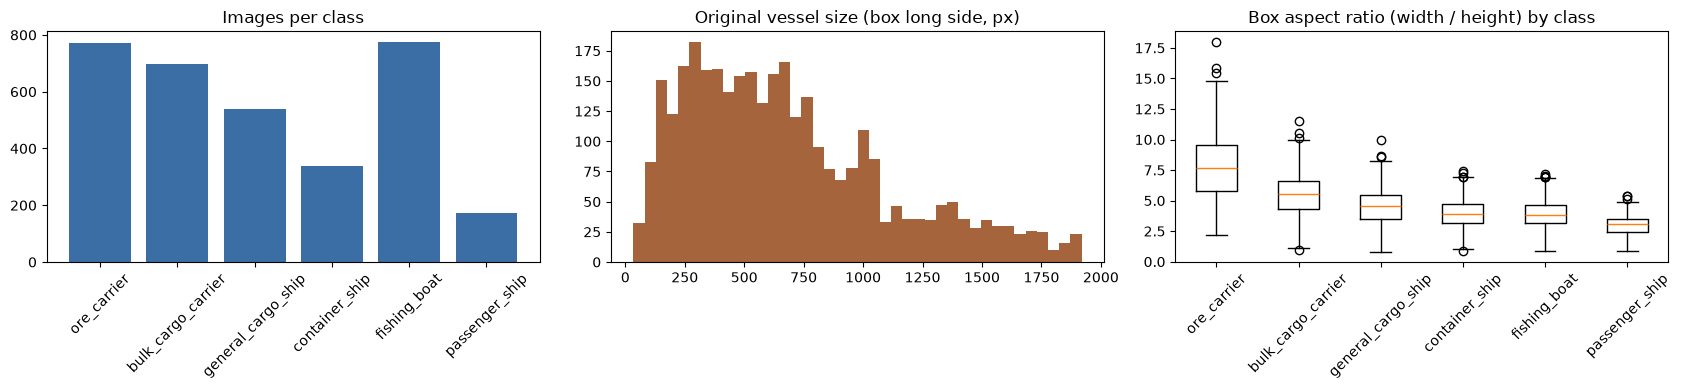

In [8]:
counts = crops["class_name"].value_counts().reindex(CLASS_NAMES)
summary = pd.DataFrame({"images": counts, "share": (counts / counts.sum()).round(3)})
print(summary.to_string())
print()
print("Total classification images:", len(crops))
print("Number of classes:          ", crops["label"].nunique())
print("Source frames:              ", crops["frame_id"].nunique())
print("Source frame size(s):       ", sorted(set(zip(crops.frame_w, crops.frame_h))))
with Image.open(crops.path.iloc[0]) as im:
    print("Stored crop size:           ", im.size, "| mode:", im.mode, f"({len(im.getbands())} channels)")

crops["long_side"] = crops[["box_w", "box_h"]].max(axis=1)
crops["aspect"] = crops["box_w"] / crops["box_h"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(CLASS_NAMES, counts.values, color="#3b6ea5")
axes[0].set_title("Images per class")
axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(crops["long_side"], bins=40, color="#a5643b")
axes[1].set_title("Original vessel size (box long side, px)")
axes[2].boxplot([crops.loc[crops.label == c, "aspect"] for c in range(NUM_CLASSES)])
axes[2].set_xticks(range(1, NUM_CLASSES + 1))
axes[2].set_xticklabels(CLASS_NAMES)
axes[2].set_title("Box aspect ratio (width / height) by class")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

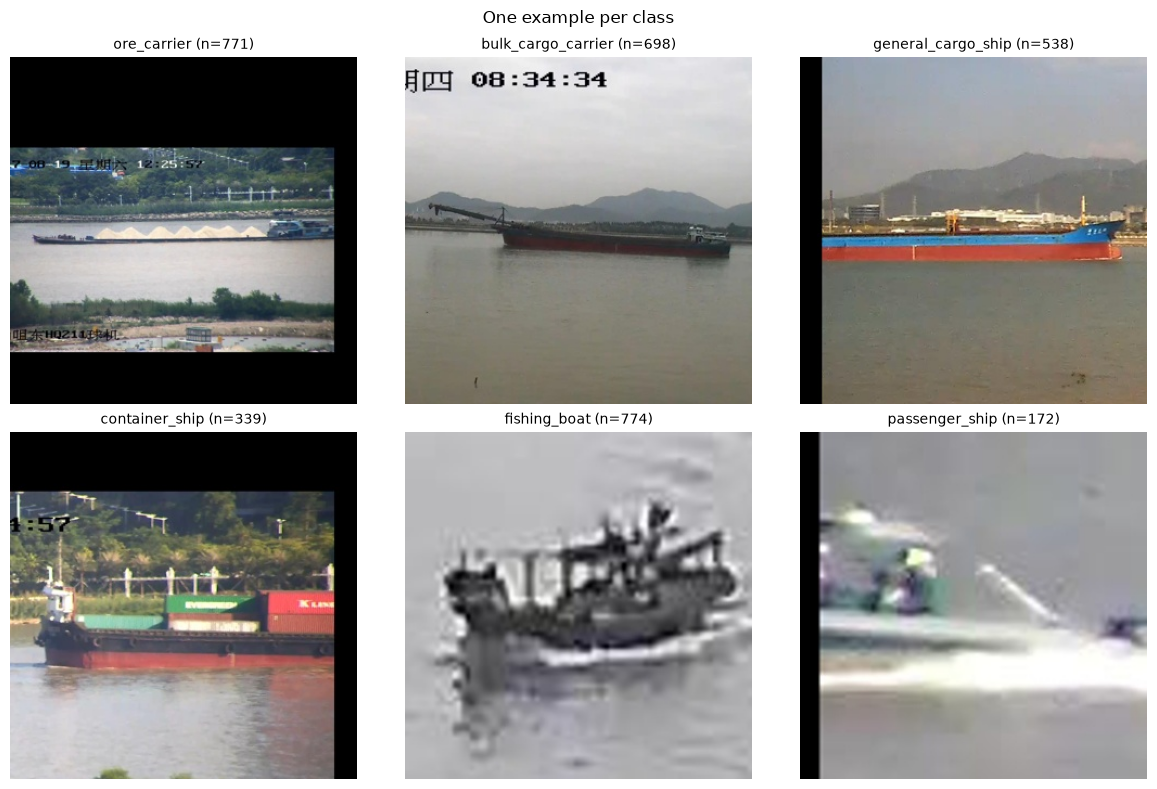

In [9]:
# ---- One example per class (randomly chosen, not hand-picked) ---------------
viz_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, c in zip(axes.ravel(), range(NUM_CLASSES)):
    pool = crops.index[crops.label == c].to_numpy()
    idx = viz_rng.choice(pool)
    ax.imshow(Image.open(crops.loc[idx, "path"]))
    ax.set_title(f"{CLASS_NAMES[c]} (n={len(pool)})", fontsize=10)
    ax.axis("off")
plt.suptitle("One example per class")
plt.tight_layout()
plt.show()

**Known limitations of the data.** Every frame comes from one stretch of Chinese coastline and a small set of fixed cameras, so backgrounds, lighting, and weather are narrow. The classes are imbalanced, and passenger ships were the rarest class in the midterm as well. Three of the six classes are cargo vessels whose silhouettes differ mostly in deck equipment, which is exactly where label noise and genuine ambiguity are most likely. Finally, my square crops include water, sky, and sometimes shoreline around each ship, so a model could learn background cues (for example, which camera position a class tends to appear in) instead of hull shape. I come back to that in the nearest-neighbor and error analysis sections.

In this sample, fishing boats (774 images, 23.5%) and ore carriers (771) are the largest classes and passenger ships the smallest (172, 5.2%), about a 4.5 to 1 ratio. No boxes were dropped for being too small. The example grid also shows something I had not planned for: many crops carry the camera's on-screen overlay text (timestamps and camera IDs like "HQ211"), and boxes near the frame edge produce black padding bars. Both are cues a model could latch onto that have nothing to do with the ship.

## 3. Train / Validation / Test Split

**Proportions:** Target proportions: 70% train, 15% validation, 15% test, created once, saved to disk, and used by both models. As the output below shows, the realized split ended up much more lopsided, and I explain why right after the split cell.

### Leakage audit

This dataset has two real leakage paths, and both come from turning a detection set into a classification set:

1. **Multiple crops from the same frame.** A frame with two ships produces two images that share the exact same water, sky, lighting, and camera. If one lands in train and the other in test, the test image is not really new.
2. **Near-identical frames from the same video.** SeaShips frames were pulled from continuous surveillance video, so the same ship can show up in several frames seconds apart. This is the "frames from the same video" case the assignment calls out.

So the unit of splitting is not the crop and not even the frame. I compute a perceptual hash for every full frame, link any two frames within a small Hamming distance of each other, and treat each connected cluster as one group. Every crop inherits its frame's group, and whole groups are assigned to a partition.

**Stratification.** Plain group splitting can leave a rare class badly underrepresented in one partition. `StratifiedGroupKFold` keeps groups intact while trying to balance class proportions, so I split into 20 folds and assign 14 to train, 3 to validation, and 3 to test.

**Augmentation** happens only inside the training data loader (Section 4), after the split exists. Nothing is augmented before splitting.

In [10]:
# ---- Near-duplicate frame clustering via perceptual hashing -----------------
import imagehash

frame_ids = sorted(crops["frame_id"].unique())
hash_bits = np.stack([
    imagehash.phash(Image.open(FRAME_DIR / f"{fid}.jpg")).hash.flatten() for fid in frame_ids
])  # shape (n_frames, 64), boolean

HAMMING_THRESHOLD = 6

parent = list(range(len(frame_ids)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

# Vectorized pairwise Hamming distances, one row at a time
for i in range(len(frame_ids) - 1):
    dists = (hash_bits[i + 1:] != hash_bits[i]).sum(axis=1)
    for j in np.where(dists <= HAMMING_THRESHOLD)[0]:
        union(i, i + 1 + j)

frame_group = {fid: f"g{find(i)}" for i, fid in enumerate(frame_ids)}
crops["group"] = crops["frame_id"].map(frame_group)

group_frame_counts = crops.groupby("group")["frame_id"].nunique().sort_values(ascending=False)
print(f"{len(frame_ids)} frames collapse into {len(group_frame_counts)} near-duplicate groups")
print(f"{(group_frame_counts > 1).sum()} groups contain more than one frame; largest group sizes:",
      group_frame_counts.head(10).tolist())
print(f"{(crops.groupby('frame_id').size() > 1).sum()} frames contribute more than one crop")

2500 frames collapse into 380 near-duplicate groups
74 groups contain more than one frame; largest group sizes: [1197, 265, 182, 118, 59, 40, 31, 26, 23, 15]
629 frames contribute more than one crop


In [11]:
# ---- Stratified, group-level split -------------------------------------------
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
fold = np.full(len(crops), -1)
for k, (_, idx) in enumerate(sgkf.split(crops, crops["label"], groups=crops["group"])):
    fold[idx] = k
crops["split"] = np.select([fold < 14, fold < 17], ["train", "val"], default="test")

# Leakage checks: no group and no frame may span two partitions
assert crops.groupby("group")["split"].nunique().max() == 1, "a near-duplicate group spans splits"
assert crops.groupby("frame_id")["split"].nunique().max() == 1, "a frame spans splits"
print("Leakage checks passed: every frame and every near-duplicate group sits in exactly one split.\n")

print(crops["split"].value_counts().reindex(["train", "val", "test"]).to_string(), "\n")
print(pd.crosstab(crops["class_name"], crops["split"]).reindex(CLASS_NAMES)[["train", "val", "test"]])

# Save the split so both models (and any rerun) use the identical partition
crops.to_csv(WORK_DIR / "split_manifest.csv", index=False)

train_idx = np.where(crops["split"] == "train")[0]
val_idx = np.where(crops["split"] == "val")[0]
test_idx = np.where(crops["split"] == "test")[0]
y_all = crops["label"].to_numpy()

Leakage checks passed: every frame and every near-duplicate group sits in exactly one split.

split
train    2949
val       172
test      171 

split               train  val  test
class_name                          
ore_carrier           669   51    51
bulk_cargo_carrier    601   49    48
general_cargo_ship    470   32    36
container_ship        309   15    15
fishing_boat          744   15    15
passenger_ship        156   10     6


What actually happened with the split. The realized partition is 2,949 train / 172 validation / 171 test images, roughly 90/5/5 instead of 70/15/15. The cause is the grouping step. The 2,500 frames collapsed into 380 groups, and one of them alone holds 1,197 frames, almost half the sample. These are fixed surveillance cameras, so a full-frame perceptual hash is dominated by the static background (shoreline, buildings, mountains), and union-find chains every frame that looks like its neighbor into one giant cluster. A group cannot be split, so that cluster went to training as a unit, and fishing boats in particular are concentrated in it (744 train vs. 15 test).

I kept this split rather than loosening the grouping to hit the target ratio, because the alternative would trade a balanced-looking table for more leakage. The cost is real, though: the test set has only 6 passenger ships and 15 each of container ships and fishing boats, so per-class results for those classes rest on very few images.

The grouping also did not catch everything. The query and retrieved image in Section 7 are the same ship from the same camera, timestamped 34 seconds apart, and one is in test while the other is in train. When the dome cameras pan or zoom between frames, the hash changes enough to miss the match. So some same-clip leakage remains, and I treat the absolute test numbers for both models as somewhat optimistic (Section 13).

## 4. Preprocessing

**Model A (ResNet18).** The `IMAGENET1K_V1` weights expect 3-channel RGB normalized with ImageNet's mean and standard deviation. Their default recipe resizes the short side to 256 and center-crops 224. I keep the normalization but swap the resize-then-crop for a direct resize of my square crop to 224x224. Since each crop was already built as a square with context around the vessel, a center crop would only throw away bow and stern on the longest ships without buying anything. That is the one justified deviation from the default recipe.

**Training augmentation (train partition only):** a mild random resized crop (75 to 100% of the area, near-square aspect), horizontal flip, and modest brightness/contrast/saturation jitter. No vertical flip, since an upside-down ship is not a realistic input. Validation and test images get the deterministic resize and normalization only.

**Model B (DINOv3)** uses the image processor that ships with the checkpoint (printed in Section 6), so its preprocessing matches what the encoder was pretrained with.

**Tensor format.** A batch has shape `[N, C, H, W]`: `N` images in the batch, `C = 3` color channels (RGB), and `H = W = 224` pixels. PyTorch convolutions expect channels before the spatial dimensions, which is why images loaded as height x width x channels get permuted by `ToTensor()`.

In [12]:
weights_a = ResNet18_Weights.IMAGENET1K_V1
default_tf = weights_a.transforms()
print("Default recipe for these weights:", default_tf)
MEAN, STD = default_tf.mean, default_tf.std
IMG_SIZE = 224

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class CropDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            img = im.convert("RGB")
        return self.transform(img), self.labels[i]

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

BATCH_SIZE = 32
loader_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(CropDataset(crops.iloc[train_idx], train_tf), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=0, generator=loader_gen)
val_loader = DataLoader(CropDataset(crops.iloc[val_idx], eval_tf), batch_size=64, num_workers=0)
test_loader = DataLoader(CropDataset(crops.iloc[test_idx], eval_tf), batch_size=64, num_workers=0)

xb, yb = next(iter(train_loader))
print("Training batch tensor shape [N, C, H, W]:", tuple(xb.shape))
print("Label batch shape:", tuple(yb.shape))

Default recipe for these weights: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Training batch tensor shape [N, C, H, W]: (32, 3, 224, 224)
Label batch shape: (32,)


## 5. Model A: Supervised Transfer Learning

**Architecture:** ResNet18, pretrained weights `IMAGENET1K_V1` (torchvision). The original 1000-way ImageNet head is replaced with a new `Linear(512, 6)` layer.

**Parameter strategy: partial fine-tuning.** I freeze the stem and `layer1` through `layer3`, and train `layer4` plus the new head.

- *Dataset size.* A few thousand crops is enough to adapt the top of the network but thin for retraining all 11 million parameters without overfitting.
- *Similarity to the pretraining domain.* ImageNet already contains ship-like categories (container ship, liner, fireboat, among others), so the low- and mid-level filters for edges, textures, and hull-like shapes should transfer. What ImageNet never had to learn is the fine distinction between an ore carrier and a bulk carrier, which lives in the most abstract features, so `layer4` is the part worth adapting.
- *Overfitting risk.* Freezing roughly three quarters of the network caps how much it can memorize the training crops. Near-duplicate frames inside the training set (allowed, since they all sit in train) make memorization easier, which is one more reason not to unfreeze everything.
- *Compute.* Fewer trainable parameters means fast epochs on a T4 and no gradient storage for the frozen blocks.

This is a different choice than the midterm, where I fully fine-tuned YOLO. There I needed the whole detector to adapt to box regression on a new domain; here the task is narrower and the comparison against a frozen encoder is cleaner if Model A is not allowed to rewrite its entire representation.

**One subtle detail about "frozen".** Setting `requires_grad=False` stops gradient updates, but BatchNorm layers still update their running mean and variance whenever the module is in training mode. To keep the frozen blocks genuinely frozen, I put them in eval mode during every training epoch.

In [13]:
model_a = resnet18(weights=weights_a)
model_a.fc = nn.Linear(model_a.fc.in_features, NUM_CLASSES)

TRAINABLE_PREFIXES = ("layer4", "fc")
for name, p in model_a.named_parameters():
    p.requires_grad = name.startswith(TRAINABLE_PREFIXES)
model_a = model_a.to(DEVICE)

FROZEN_MODULES = [model_a.conv1, model_a.bn1, model_a.layer1, model_a.layer2, model_a.layer3]
def set_train_mode(model):
    model.train()
    for m in FROZEN_MODULES:
        m.eval()   # keeps BatchNorm running statistics fixed in frozen blocks

block_rows = []
for block in ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"]:
    params = list(getattr(model_a, block).parameters())
    n = sum(p.numel() for p in params)
    block_rows.append({"block": block, "parameters": n,
                       "status": "trainable" if params[0].requires_grad else "frozen"})
block_table = pd.DataFrame(block_rows)
print(block_table.to_string(index=False))

total_a = sum(p.numel() for p in model_a.parameters())
trainable_a = sum(p.numel() for p in model_a.parameters() if p.requires_grad)
encoder_trainable_a = sum(p.numel() for n, p in model_a.named_parameters()
                          if p.requires_grad and not n.startswith("fc"))
print(f"\nTotal parameters:     {total_a:,}")
print(f"Trainable parameters: {trainable_a:,} ({trainable_a / total_a:.1%})")
print(f"  of which encoder (layer4): {encoder_trainable_a:,}; new head: {trainable_a - encoder_trainable_a:,}")
print("Output classes:", model_a.fc.out_features)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\dbely/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:25<00:00, 1.86MB/s]

 block  parameters    status
 conv1        9408    frozen
   bn1         128    frozen
layer1      147968    frozen
layer2      525568    frozen
layer3     2099712    frozen
layer4     8393728 trainable
    fc        3078 trainable

Total parameters:     11,179,590
Trainable parameters: 8,396,806 (75.1%)
  of which encoder (layer4): 8,393,728; new head: 3,078
Output classes: 6


### Training setup

- **Loss:** cross-entropy (unweighted; class imbalance is handled at evaluation time with macro-averaged metrics, and noted as a limitation)
- **Optimizer:** AdamW, weight decay 1e-4, with two learning rates: 1e-4 for the pretrained `layer4` (small nudges to features that already work) and 1e-3 for the freshly initialized head
- **Batch size:** 32
- **Epochs:** Epochs: up to 10, with early stopping on validation loss (patience 3). I cut this from 20 because training ran on a CPU. The weights from the best validation epoch are restored before testing.

The validation set is used only to pick the stopping epoch. The test set is not touched until Section 8.

In [14]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {"params": model_a.layer4.parameters(), "lr": 1e-4},
    {"params": model_a.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-4)

MAX_EPOCHS = 10
PATIENCE = 3

def run_epoch(model, loader, train):
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

history, best_val, best_state, best_epoch, wait = [], float("inf"), None, 0, 0
t0 = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    set_train_mode(model_a)
    tr_loss, tr_acc = run_epoch(model_a, train_loader, train=True)
    model_a.eval()
    va_loss, va_acc = run_epoch(model_a, val_loader, train=False)
    history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc, val_acc=va_acc))
    print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f}")
    if va_loss < best_val - 1e-4:
        best_val, best_epoch, wait = va_loss, epoch, 0
        best_state = copy.deepcopy(model_a.state_dict())
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping: no validation improvement for {PATIENCE} epochs")
            break
train_time_a = time.time() - t0

model_a.load_state_dict(best_state)
model_a.eval()
history = pd.DataFrame(history)
print(f"\nBest epoch: {best_epoch} (val loss {best_val:.4f}); training time {train_time_a:.0f}s")

epoch  1 | train loss 0.7144 acc 0.741 | val loss 0.4723 acc 0.797
epoch  2 | train loss 0.2848 acc 0.898 | val loss 0.3527 acc 0.884
epoch  3 | train loss 0.1791 acc 0.941 | val loss 0.2936 acc 0.884
epoch  4 | train loss 0.1437 acc 0.950 | val loss 0.3491 acc 0.878
epoch  5 | train loss 0.1089 acc 0.959 | val loss 0.2221 acc 0.936
epoch  6 | train loss 0.0997 acc 0.963 | val loss 0.2366 acc 0.924
epoch  7 | train loss 0.0778 acc 0.974 | val loss 0.2660 acc 0.930
epoch  8 | train loss 0.0542 acc 0.980 | val loss 0.1959 acc 0.936
epoch  9 | train loss 0.0965 acc 0.963 | val loss 0.1869 acc 0.930
epoch 10 | train loss 0.0812 acc 0.971 | val loss 0.2509 acc 0.924

Best epoch: 9 (val loss 0.1869); training time 1283s


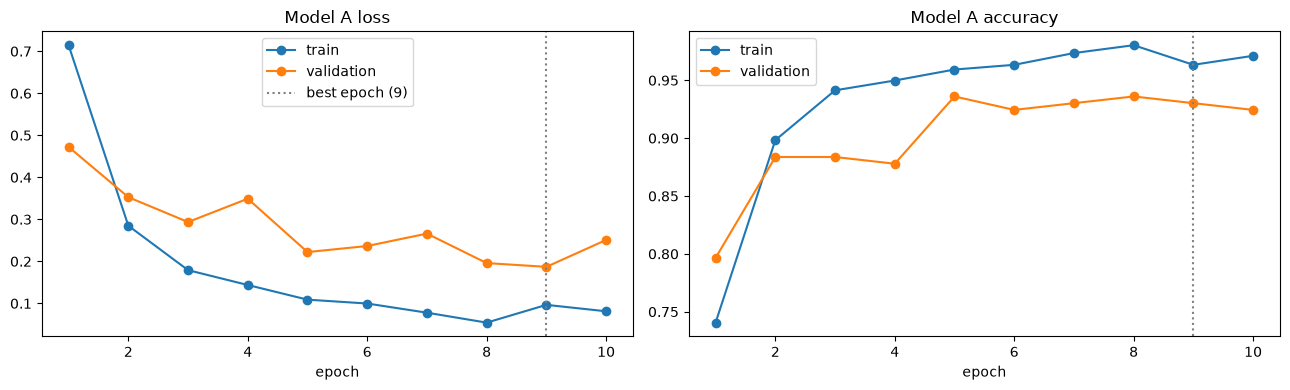

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.epoch, history.train_loss, marker="o", label="train")
axes[0].plot(history.epoch, history.val_loss, marker="o", label="validation")
axes[0].axvline(best_epoch, color="gray", linestyle=":", label=f"best epoch ({best_epoch})")
axes[0].set_title("Model A loss")
axes[1].plot(history.epoch, history.train_acc, marker="o", label="train")
axes[1].plot(history.epoch, history.val_acc, marker="o", label="validation")
axes[1].axvline(best_epoch, color="gray", linestyle=":")
axes[1].set_title("Model A accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

**Reading the training history.**

Training loss fell steadily from 0.714 to about 0.05 to 0.10, and validation loss fell from 0.472 to its best value of 0.187 at epoch 9, so this is not underfitting. Validation loss was bumpy (spikes at epochs 4, 7, and 10), which I mostly attribute to the validation set being only 172 images, where one image is worth about 0.6 percentage points of accuracy.

By the end there is a gap of about 4 to 5 points between training accuracy (0.97 to 0.98) and validation accuracy (0.92 to 0.94), and validation loss jumped at epoch 10. That is the start of overfitting rather than a serious case of it. Early stopping never fired because the run hit the 10-epoch cap first, and the best epoch was the second to last. A longer run might have squeezed out a little more, but the epoch 10 uptick suggests not much. Overall I read this as reasonable generalization with the frozen early layers doing their job of limiting memorization.

Validation loss sitting below training loss at epoch 1 is expected: augmentation makes the training images harder than the clean validation images, and the training loss is averaged over an epoch in which the model started from scratch on the new head.

## 6. Model B: DINOv3 Frozen Representations

DINOv3 learned its features through self-distillation on a very large unlabeled image collection: a student network learns to match a teacher network's output across different views of the same image. It never saw ship-type labels, or any labels at all. So whatever separates an ore carrier from a container ship in its embedding space got there without supervision.

**Pipeline:** image, then the frozen DINOv3 encoder, then the CLS-token embedding (`pooler_output`), then a linear classifier. No encoder weight is updated at any point; the cell below checks that numerically instead of just asserting it.

> **Checkpoint note:** set `DINO_CHECKPOINT` to the exact checkpoint used in the Week 6 demo if it differs from the ViT-S/16 default below. The ViT-B/16 version (`facebook/dinov3-vitb16-pretrain-lvd1689m`, 768-dim embeddings) is a drop-in swap.

In [16]:
# Gated model: uncomment if you did not add HF_TOKEN to Colab Secrets
from huggingface_hub import login
login()

from transformers import AutoImageProcessor, AutoModel

DINO_CHECKPOINT = "facebook/dinov3-vits16-pretrain-lvd1689m"   # match the Week 6 checkpoint

processor = AutoImageProcessor.from_pretrained(DINO_CHECKPOINT)
dino = AutoModel.from_pretrained(DINO_CHECKPOINT).to(DEVICE).eval()
for p in dino.parameters():
    p.requires_grad_(False)

def param_checksum(model):
    return sum(p.detach().double().sum().item() for p in model.parameters())

dino_params = sum(p.numel() for p in dino.parameters())
checksum_before = param_checksum(dino)
print("Checkpoint:", DINO_CHECKPOINT)
print(f"Encoder parameters: {dino_params:,} (all frozen: "
      f"{all(not p.requires_grad for p in dino.parameters())})")
print("\nDINOv3 preprocessing:\n", processor)

c:\Users\dbely\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\dbely\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dbely\.cache\huggingface\hub\models--facebook--dinov3-vits16-pretrain-lvd1689m. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to 

Checkpoint: facebook/dinov3-vits16-pretrain-lvd1689m
Encoder parameters: 21,596,544 (all frozen: True)

DINOv3 preprocessing:
 DINOv3ViTImageProcessor {
  "data_format": "channels_first",
  "default_to_square": true,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.485,
    0.456,
    0.406
  ],
  "image_processor_type": "DINOv3ViTImageProcessor",
  "image_std": [
    0.229,
    0.224,
    0.225
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}



In [17]:
@torch.no_grad()
def embed_paths(paths, batch_size=64):
    out = []
    for i in range(0, len(paths), batch_size):
        imgs = []
        for p in paths[i:i + batch_size]:
            with Image.open(p) as im:
                imgs.append(im.convert("RGB"))
        inputs = processor(images=imgs, return_tensors="pt").to(DEVICE)
        out.append(dino(**inputs).pooler_output.float().cpu())
    return torch.cat(out).numpy()

t0 = time.time()
emb = embed_paths(crops["path"].tolist())
embed_time = time.time() - t0
np.save(WORK_DIR / "dinov3_embeddings.npy", emb)

checksum_after = param_checksum(dino)
EMB_DIM = emb.shape[1]
print(f"Embeddings generated: {emb.shape[0]:,} (one per image), dimension {EMB_DIM}")
print(f"Embedding time: {embed_time:.0f}s")
print("Encoder weights changed during embedding?", checksum_before != checksum_after)

Embeddings generated: 3,292 (one per image), dimension 384
Embedding time: 307s
Encoder weights changed during embedding? False


### Linear probe

A multinomial logistic regression on the embeddings, nothing deeper. If a straight line (well, a set of hyperplanes) can separate the classes in DINOv3's space, the class information was already there before I trained anything.

- **Trained:** the probe's weight matrix (`EMB_DIM x 6`) and 6 biases.
- **Frozen:** every DINOv3 encoder parameter.

Embeddings are L2-normalized first so the probe and the cosine-similarity analysis in Sections 7 and 10 live in the same geometry. The inverse regularization strength `C` is chosen on the validation set; the final probe is fit on the training set only, the same data Model A trained on.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize
from sklearn.metrics import f1_score

X_all = normalize(emb)   # L2-normalized embeddings
X_tr, X_va, X_te = X_all[train_idx], X_all[val_idx], X_all[test_idx]
y_tr, y_va, y_te = y_all[train_idx], y_all[val_idx], y_all[test_idx]

c_rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    clf = LogisticRegression(C=C, max_iter=5000)
    clf.fit(X_tr, y_tr)
    c_rows.append({"C": C,
                   "train_acc": clf.score(X_tr, y_tr),
                   "val_acc": clf.score(X_va, y_va),
                   "val_macro_f1": f1_score(y_va, clf.predict(X_va), average="macro")})
c_table = pd.DataFrame(c_rows)
print(c_table.round(3).to_string(index=False))

best_C = c_table.loc[c_table.val_macro_f1.idxmax(), "C"]
t0 = time.time()
probe = LogisticRegression(C=best_C, max_iter=5000).fit(X_tr, y_tr)
train_time_b = time.time() - t0
trainable_b = probe.coef_.size + probe.intercept_.size
print(f"\nSelected C = {best_C}; probe fit time {train_time_b:.1f}s")
print(f"Trainable parameters: {probe.coef_.shape[0]} x {probe.coef_.shape[1]} weights + "
      f"{probe.intercept_.size} biases = {trainable_b:,}")
print(f"Frozen encoder parameters: {dino_params:,}")

     C  train_acc  val_acc  val_macro_f1
  0.01      0.524    0.523         0.294
  0.10      0.787    0.797         0.664
  1.00      0.890    0.860         0.804
 10.00      0.955    0.826         0.782
100.00      0.984    0.831         0.774

Selected C = 1.0; probe fit time 0.1s
Trainable parameters: 6 x 384 weights + 6 biases = 2,310
Frozen encoder parameters: 21,596,544


## 7. Under-the-Hood Demonstration (Option C): Cosine Similarity in DINOv3 Space

Cosine similarity is the quantity the nearest-neighbor retrieval in Section 10 ranks by, so it is worth computing once by hand:

$$\cos(\mathbf{x}, \mathbf{y}) = \frac{\mathbf{x} \cdot \mathbf{y}}{\lVert \mathbf{x} \rVert \, \lVert \mathbf{y} \rVert}$$

The embeddings have hundreds of dimensions, so the hand calculation uses only the **first 5 dimensions**. That part is purely pedagogical: a 5-dimensional cosine is not the real similarity. The full-dimension value is then computed in Python three independent ways and checked against the number the retrieval actually used.

The query is a test image picked at random (not by label), and the retrieved embedding is its most similar training image.

Query: frame_01086_0   Retrieved: frame_00645_0

 i |      x_i      |      y_i      |   x_i * y_i
 0 |      0.87850  |      0.75671  |      0.66477
 1 |      0.61116  |      0.35463  |      0.21674
 2 |      0.23851  |      0.07186  |      0.01714
 3 |     -0.55108  |     -0.62055  |      0.34197
 4 |      0.21464  |      0.55052  |      0.11816

Dot product (5 dims):  (0.66477) + (0.21674) + (0.01714) + (0.34197) + (0.11816) = 1.35878
||x|| (5 dims) = sqrt(0.77176 + 0.37352 + 0.05689 + 0.30369 + 0.04607) = 1.24576
||y|| (5 dims) = sqrt(0.57261 + 0.12576 + 0.00516 + 0.38508 + 0.30307) = 1.17970
cos (5 dims) = 1.35878 / (1.24576 x 1.17970) = 0.92458
(pedagogical only: 5 of the dimensions, not the real similarity)

Full 384-dim cosine, NumPy formula:          0.846834
Full 384-dim cosine, torch.cosine_similarity: 0.846834
Value used by the retrieval (normalized dot):  0.846834
All three agree.


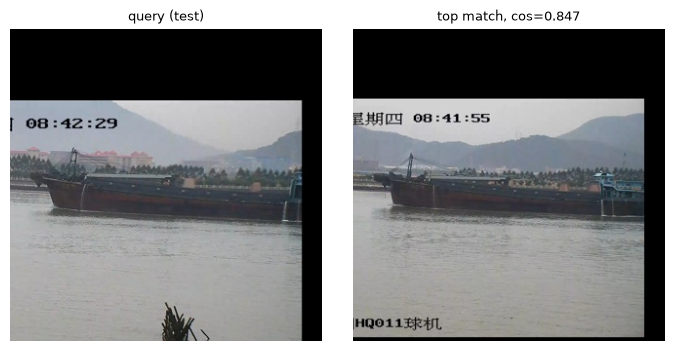

In [19]:
demo_rng = np.random.default_rng(SEED + 1)
q_pos = demo_rng.choice(len(test_idx))          # position within the test set
q_global = test_idx[q_pos]
sims_q = X_te[q_pos] @ X_tr.T                    # cosine similarity to every training image
nn_pos = int(np.argmax(sims_q))
nn_global = train_idx[nn_pos]

x = emb[q_global].astype(np.float64)   # raw (unnormalized) embeddings
y = emb[nn_global].astype(np.float64)

K = 5
print(f"Query: {crops.crop_id[q_global]}   Retrieved: {crops.crop_id[nn_global]}\n")
print(" i |      x_i      |      y_i      |   x_i * y_i")
for i in range(K):
    print(f"{i:2d} | {x[i]:12.5f}  | {y[i]:12.5f}  | {x[i]*y[i]:12.5f}")

dot_k = float(np.sum(x[:K] * y[:K]))
nx_k = float(np.sqrt(np.sum(x[:K] ** 2)))
ny_k = float(np.sqrt(np.sum(y[:K] ** 2)))
print(f"\nDot product (5 dims):  {' + '.join(f'({v:.5f})' for v in x[:K]*y[:K])} = {dot_k:.5f}")
print(f"||x|| (5 dims) = sqrt({' + '.join(f'{v:.5f}' for v in x[:K]**2)}) = {nx_k:.5f}")
print(f"||y|| (5 dims) = sqrt({' + '.join(f'{v:.5f}' for v in y[:K]**2)}) = {ny_k:.5f}")
print(f"cos (5 dims) = {dot_k:.5f} / ({nx_k:.5f} x {ny_k:.5f}) = {dot_k / (nx_k * ny_k):.5f}")
print("(pedagogical only: 5 of the dimensions, not the real similarity)\n")

# ---- Python verification on the full embedding --------------------------------
cos_numpy = float(x @ y / (np.linalg.norm(x) * np.linalg.norm(y)))
cos_torch = float(F.cosine_similarity(torch.tensor(x), torch.tensor(y), dim=0))
cos_retrieval = float(sims_q[nn_pos])
print(f"Full {EMB_DIM}-dim cosine, NumPy formula:          {cos_numpy:.6f}")
print(f"Full {EMB_DIM}-dim cosine, torch.cosine_similarity: {cos_torch:.6f}")
print(f"Value used by the retrieval (normalized dot):  {cos_retrieval:.6f}")
assert abs(cos_numpy - cos_torch) < 1e-6 and abs(cos_numpy - cos_retrieval) < 1e-4
print("All three agree.")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, idx, title in [(axes[0], q_global, "query (test)"), (axes[1], nn_global, f"top match, cos={cos_numpy:.3f}")]:
    ax.imshow(Image.open(crops.path[idx])); ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**What this means inside the model.** Cosine similarity ignores how long the two vectors are and looks only at the angle between them, so it asks whether two images activate the same *pattern* of features rather than how strongly. A value near 1 means DINOv3 encodes the two images almost identically; near 0 means unrelated feature patterns. The linear probe works in the same space: after L2 normalization, every embedding sits on a unit sphere, and each class weight vector scores an image by essentially the same dot product computed above. If same-class images cluster in angle, a linear probe will do well, which is why this one number connects the retrieval results and the probe's accuracy.

> The 5-dimension calculation gave 0.925, well above the true 384-dimension similarity of 0.847. That gap is the point of using every dimension: five coordinates happened to agree more than the full vector does. The pair itself is worth a second look. Both images show the same vessel from the same camera, with on-screen timestamps of 08:42:29 and 08:41:55, so this "neighbor" is really the same scene 34 seconds earlier. It sits in the training set while the query sits in test, which is exactly the frames-from-the-same-video leakage the audit was supposed to prevent (see Section 3).

## 8. Evaluation on the Same Test Set

Both models are scored once, on the same untouched test images. For a six-class problem I report accuracy plus **macro-averaged** precision, recall, and F1, meaning each class counts equally regardless of size, so the rare classes cannot hide behind the common ones. Per-class reports and confusion matrices follow.

===== Model A: ResNet18 partial fine-tune =====
                    precision    recall  f1-score   support

       ore_carrier      1.000     0.941     0.970        51
bulk_cargo_carrier      0.878     0.896     0.887        48
general_cargo_ship      0.917     0.917     0.917        36
    container_ship      1.000     1.000     1.000        15
      fishing_boat      0.882     1.000     0.938        15
    passenger_ship      1.000     1.000     1.000         6

          accuracy                          0.936       171
         macro avg      0.946     0.959     0.952       171
      weighted avg      0.938     0.936     0.936       171



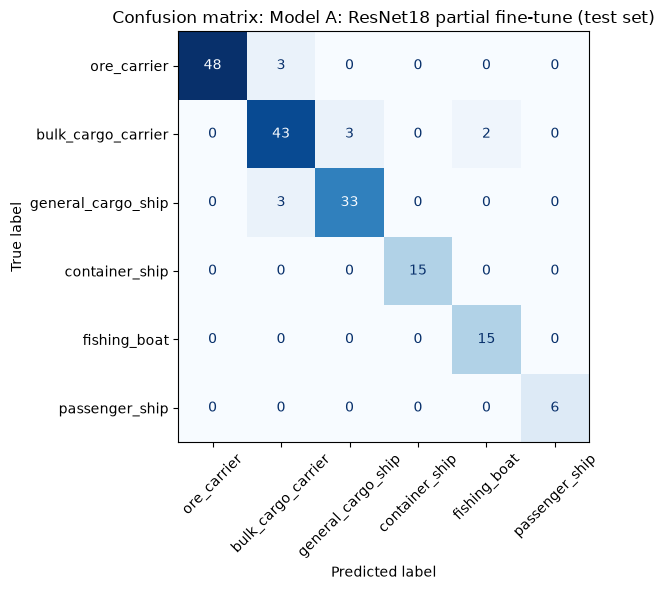

In [20]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)

@torch.no_grad()
def predict_model_a(loader):
    preds = []
    for xb, _ in loader:
        preds.append(model_a(xb.to(DEVICE)).argmax(1).cpu())
    return torch.cat(preds).numpy()

pred_a = predict_model_a(test_loader)
pred_b = probe.predict(X_te)

def evaluate(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASS_NAMES,
                                            xticks_rotation=45, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Confusion matrix: {name} (test set)")
    plt.tight_layout(); plt.show()
    return {"Accuracy": acc, "Macro Precision": p, "Macro Recall": r, "Macro F1": f}

metrics_a = evaluate(y_te, pred_a, "Model A: ResNet18 partial fine-tune")

===== Model B: DINOv3 + linear probe =====
                    precision    recall  f1-score   support

       ore_carrier      0.920     0.902     0.911        51
bulk_cargo_carrier      0.857     0.875     0.866        48
general_cargo_ship      0.872     0.944     0.907        36
    container_ship      1.000     0.867     0.929        15
      fishing_boat      0.923     0.800     0.857        15
    passenger_ship      0.714     0.833     0.769         6

          accuracy                          0.889       171
         macro avg      0.881     0.870     0.873       171
      weighted avg      0.892     0.889     0.889       171



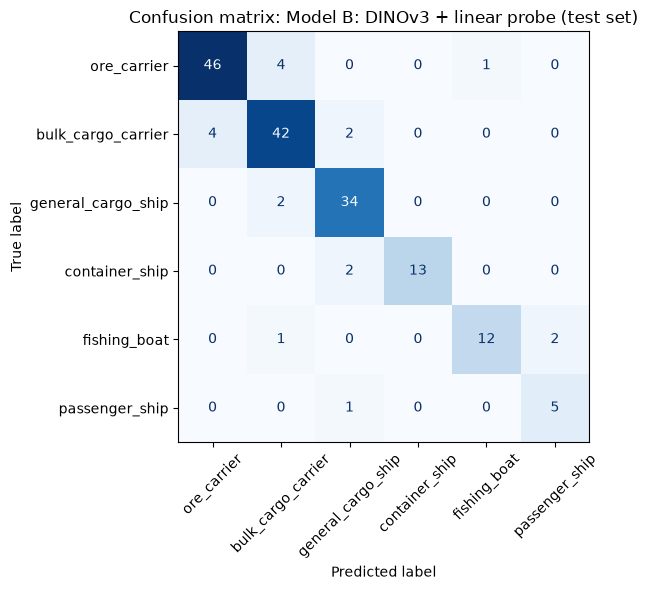

In [21]:
metrics_b = evaluate(y_te, pred_b, "Model B: DINOv3 + linear probe")

## 9. Model Comparison

,Supervised Transfer Model (ResNet18),DINOv3 + Linear Probe
Accuracy,0.936,0.889
Macro Precision,0.946,0.881
Macro Recall,0.959,0.870
Macro F1,0.952,0.873
Encoder Parameters Updated?,"Yes, layer4 only (8,393,728)",No
Trainable Parameters,"8,396,806","2,310"
Training compute,"10 epochs, 1283s on cpu",one forward pass per image (307s) + probe fit ...


             class  test n  F1 ResNet18  F1 DINOv3 probe   better
       ore_carrier      51        0.970            0.911 ResNet18
bulk_cargo_carrier      48        0.887            0.866 ResNet18
general_cargo_ship      36        0.917            0.907 ResNet18
    container_ship      15        1.000            0.929 ResNet18
      fishing_boat      15        0.938            0.857 ResNet18
    passenger_ship       6        1.000            0.769 ResNet18


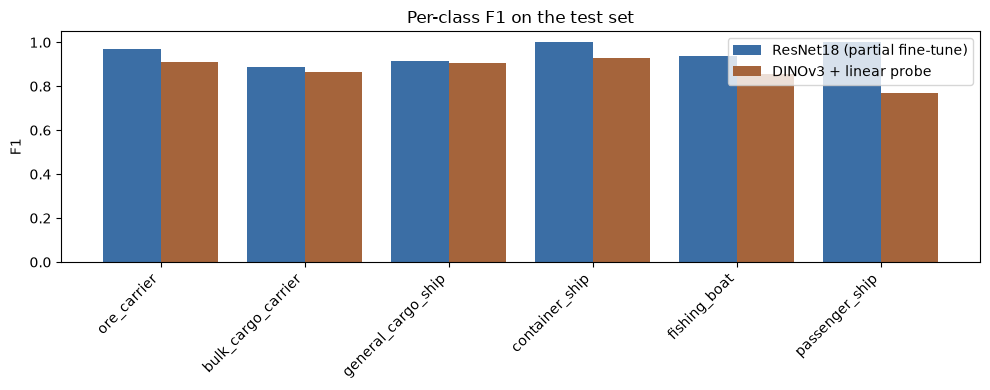

In [22]:
comparison = pd.DataFrame({
    "Supervised Transfer Model (ResNet18)": {
        **{k: f"{v:.3f}" for k, v in metrics_a.items()},
        "Encoder Parameters Updated?": f"Yes, layer4 only ({encoder_trainable_a:,})",
        "Trainable Parameters": f"{trainable_a:,}",
        "Training compute": f"{len(history)} epochs, {train_time_a:.0f}s on {DEVICE}",
    },
    "DINOv3 + Linear Probe": {
        **{k: f"{v:.3f}" for k, v in metrics_b.items()},
        "Encoder Parameters Updated?": "No",
        "Trainable Parameters": f"{trainable_b:,}",
        "Training compute": f"one forward pass per image ({embed_time:.0f}s) + probe fit ({train_time_b:.1f}s)",
    },
})
display(comparison)

_, _, f1_a, _ = precision_recall_fscore_support(y_te, pred_a, labels=range(NUM_CLASSES), zero_division=0)
_, _, f1_b, _ = precision_recall_fscore_support(y_te, pred_b, labels=range(NUM_CLASSES), zero_division=0)
per_class = pd.DataFrame({"class": CLASS_NAMES, "test n": np.bincount(y_te, minlength=NUM_CLASSES),
                          "F1 ResNet18": f1_a.round(3), "F1 DINOv3 probe": f1_b.round(3)})
per_class["better"] = np.where(f1_a > f1_b, "ResNet18", np.where(f1_b > f1_a, "DINOv3", "tie"))
print(per_class.to_string(index=False))

xpos = np.arange(NUM_CLASSES)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(xpos - 0.2, f1_a, 0.4, label="ResNet18 (partial fine-tune)", color="#3b6ea5")
ax.bar(xpos + 0.2, f1_b, 0.4, label="DINOv3 + linear probe", color="#a5643b")
ax.set_xticks(xpos); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("F1"); ax.set_ylim(0, 1.05); ax.set_title("Per-class F1 on the test set"); ax.legend()
plt.tight_layout(); plt.show()

### Answering the comparison questions

>Which approach produced the strongest overall test performance? The fine-tuned ResNet18, clearly. It reached 0.936 accuracy and 0.952 macro F1, against 0.889 accuracy and 0.873 macro F1 for the DINOv3 probe. Macro F1 is the fairer comparison here because it does not let the large cargo classes carry the score.

Did the same model perform best for every class? Yes, ResNet18 had the higher F1 on all six classes. The gap was small for the cargo classes (general cargo 0.917 vs. 0.907, bulk carrier 0.887 vs. 0.866) and largest for passenger ships (1.000 vs. 0.769) and fishing boats (0.938 vs. 0.857). I would not lean on the passenger ship gap. There are only 6 in the test set, and the probe's lower score comes from getting 5 of them right and labeling 2 fishing boats as passenger ships.

How much training did each require? Very different amounts. ResNet18 updated 8,396,806 parameters through 10 epochs of backpropagation, about 21 minutes on my CPU. The probe trained 2,310 parameters (roughly 3,600 times fewer), and fitting it took 0.1 seconds. Most of Model B's cost was the single forward pass to embed every image, about 5 minutes, and that step involves no training at all.

What information was already present in the DINOv3 representation before the probe was trained? Most of it. Classifying each test image by its single nearest training image, with zero trained parameters, already reached 0.854 accuracy. The probe only added a few points on top of that (0.889). So the separation between vessel types was largely there in DINOv3's embedding space before I touched a label. I would temper that slightly: the leftover same-clip leakage helps nearest-neighbor lookups more than anything, so part of that 0.854 comes from near-duplicates.

Did fine-tuning the supervised representation appear to provide an advantage? Yes, about 5 points of accuracy and 8 points of macro F1. Whether that is worth it depends on the setting. Here it cost thousands of times more trainable parameters and about 4 times the wall-clock time on the same machine. The two models also differ in more than training method (CNN vs. ViT, ImageNet labels vs. self-supervised pretraining), so I cannot attribute the whole gap to fine-tuning.

Which approach would I choose if labeled data were much scarcer? The DINOv3 probe. Its features did not need any of my labels to form, and with only 2,310 parameters to fit, it has far less room to memorize a small training set. ResNet18's layer4 has over 8 million parameters, and with a few hundred images I would expect it to overfit badly or need to be frozen entirely. I have not tested this directly, so it is a prediction rather than a result.

## 10. Nearest-Neighbor Analysis

Three test images are drawn at random, without looking at their labels. For each, I compute cosine similarity to every training embedding and show the three closest training images. Labels are added to the titles only after the neighbors have been retrieved, for interpretation.

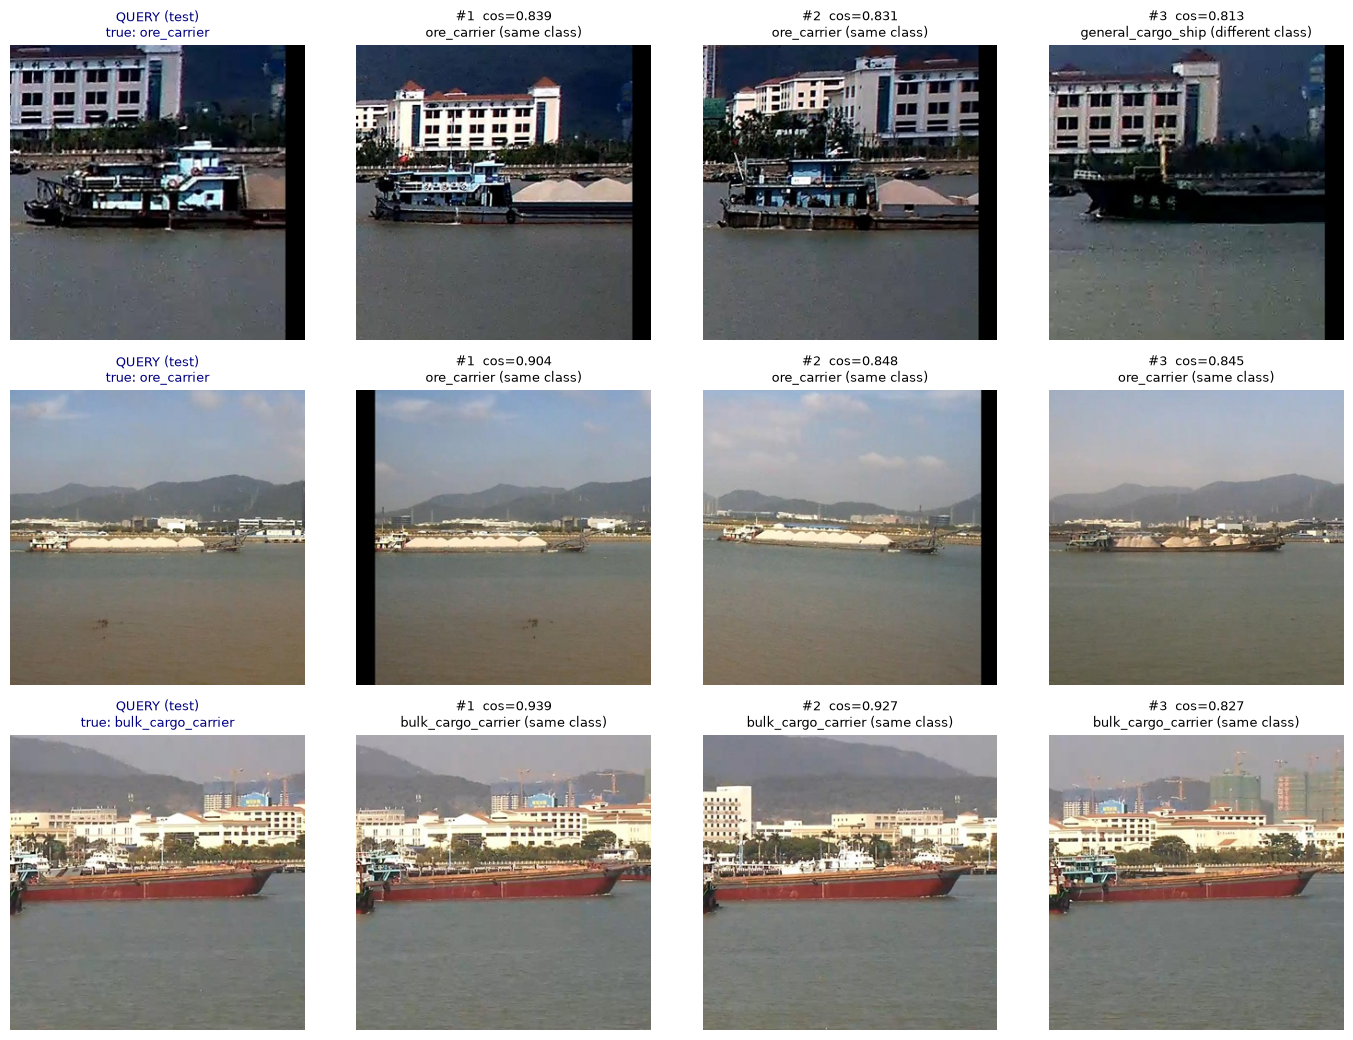

1-nearest-neighbor test accuracy (no training at all): 0.854


In [23]:
nn_rng = np.random.default_rng(SEED + 2)
query_positions = nn_rng.choice(len(test_idx), size=3, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(14, 10.5))
for row, q in enumerate(query_positions):
    sims = X_te[q] @ X_tr.T
    top3 = np.argsort(-sims)[:3]
    qg = test_idx[q]
    axes[row, 0].imshow(Image.open(crops.path[qg]))
    axes[row, 0].set_title(f"QUERY (test)\ntrue: {CLASS_NAMES[y_te[q]]}", fontsize=9, color="navy")
    for col, t in enumerate(top3, start=1):
        tg = train_idx[t]
        match = "same class" if y_tr[t] == y_te[q] else "different class"
        axes[row, col].imshow(Image.open(crops.path[tg]))
        axes[row, col].set_title(f"#{col}  cos={sims[t]:.3f}\n{CLASS_NAMES[y_tr[t]]} ({match})", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout(); plt.show()

# How much class information is there with zero training? A 1-nearest-neighbor check.
nn1 = np.argmax(X_te @ X_tr.T, axis=1)
print(f"1-nearest-neighbor test accuracy (no training at all): {np.mean(y_tr[nn1] == y_te):.3f}")

**Are the neighbors reasonable?**

>Are the neighbors reasonable? Mostly yes, but for a mix of good and not-so-good reasons.

Row 1 (true ore carrier): the top two neighbors are ore carriers with the same blue-cabin, sand-pile profile, which is a semantic match. The third is a general cargo ship, and what it shares with the query is the scene, not the vessel: the same white buildings in the background, the same dark water, and a dark hull. That is the background shortcut I worried about in Section 2 showing up directly.

Row 2 (true ore carrier): all three neighbors are distant ore carriers loaded with sand, against the same mountain skyline. Here semantics and scene agree, so it is hard to say which one drove the match.

Row 3 (true bulk carrier): all three neighbors are bulk carriers, and the top two (0.939 and 0.927) look like the same red-hulled ship at the same spot in front of the same buildings. That is either the same vessel recorded at another time or a frame from the same clip that the hash missed.

The 1-nearest-neighbor accuracy of 0.854 with no training fits this picture. The embedding space really does put same-type ships near each other, but scene similarity and near-duplicates help it along, which is why I would not read 0.854 as pure ship recognition.

## 11. Error Analysis

The cases below are pulled automatically from the test predictions: one image Model A got wrong, one the DINOv3 probe got wrong, and one where the two models disagree, chosen to be three different images where possible. Each is shown twice, as the crop the models saw and in its full source frame, because the frame context is often what explains the mistake.

Model A wrong: 11 | DINOv3 wrong: 19 | both wrong: 3 | disagree: 24 | test images: 171


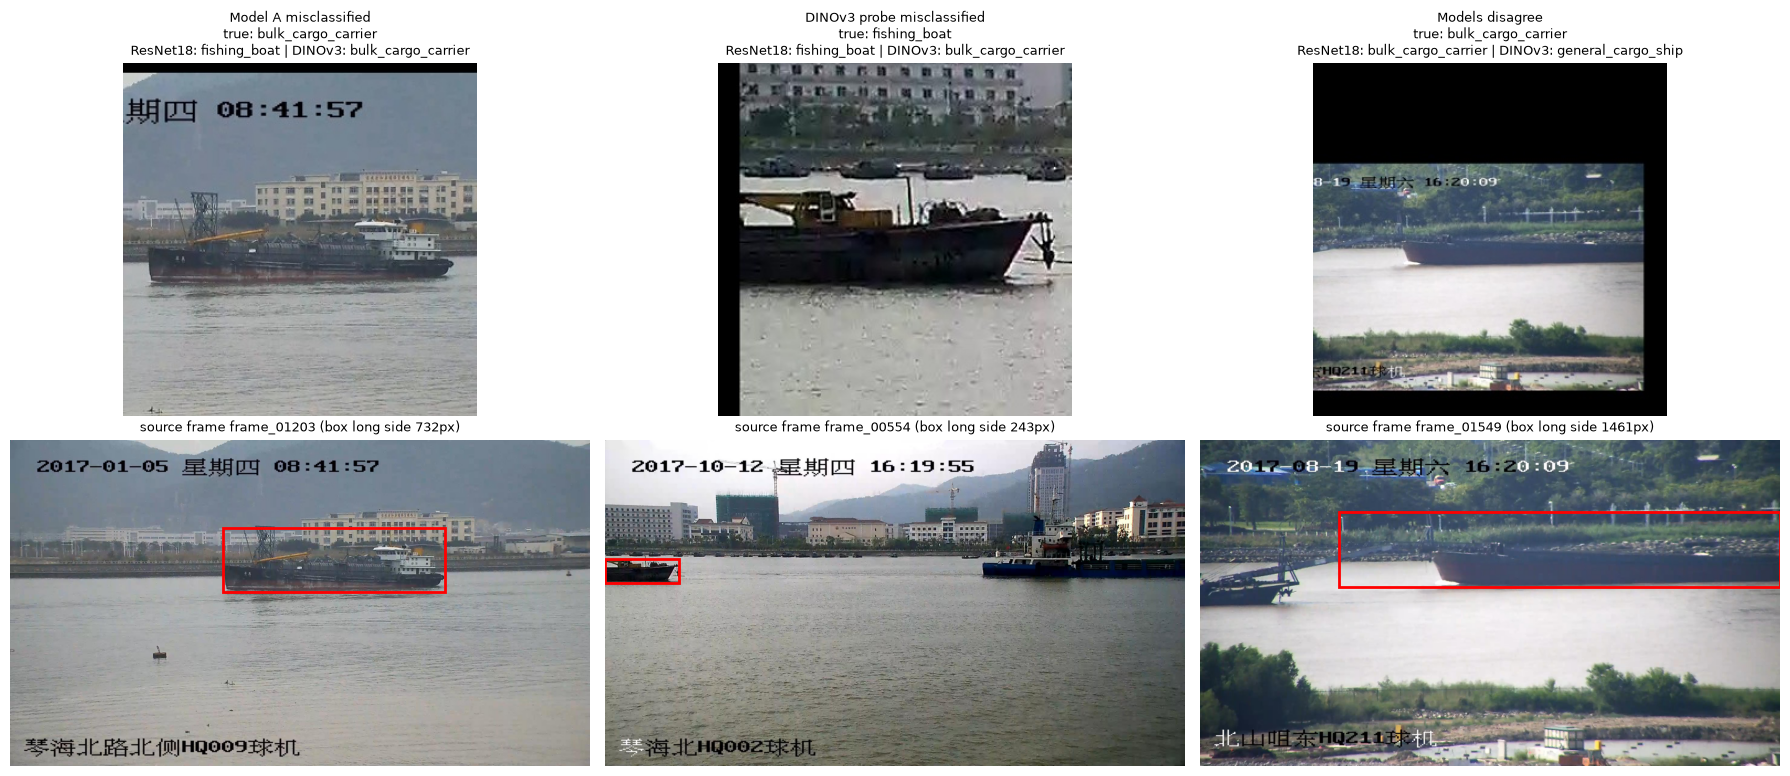

In [24]:
test_df = crops.iloc[test_idx].copy().reset_index(drop=True)
test_df["pred_a"], test_df["pred_b"] = pred_a, pred_b
a_wrong = test_df.label != test_df.pred_a
b_wrong = test_df.label != test_df.pred_b
disagree = test_df.pred_a != test_df.pred_b
print(f"Model A wrong: {a_wrong.sum()} | DINOv3 wrong: {b_wrong.sum()} | both wrong: {(a_wrong & b_wrong).sum()} | "
      f"disagree: {disagree.sum()} | test images: {len(test_df)}")

err_rng = np.random.default_rng(SEED + 3)
chosen, used = [], set()
for label, mask in [("Model A misclassified", a_wrong), ("DINOv3 probe misclassified", b_wrong),
                    ("Models disagree", disagree)]:
    pool = [i for i in np.where(mask)[0] if i not in used] or list(np.where(mask)[0])
    if pool:
        i = int(err_rng.choice(pool)); used.add(i); chosen.append((label, i))
    else:
        print(f"No test images in category: {label}")

fig, axes = plt.subplots(2, len(chosen), figsize=(6 * len(chosen), 8), squeeze=False)
for col, (label, i) in enumerate(chosen):
    r = test_df.iloc[i]
    axes[0, col].imshow(Image.open(r.path))
    axes[0, col].set_title(f"{label}\ntrue: {CLASS_NAMES[r.label]}\nResNet18: {CLASS_NAMES[r.pred_a]} | "
                           f"DINOv3: {CLASS_NAMES[r.pred_b]}", fontsize=9)
    axes[1, col].imshow(Image.open(FRAME_DIR / f"{r.frame_id}.jpg"))
    axes[1, col].add_patch(patches.Rectangle((r.box_x, r.box_y), r.box_w, r.box_h,
                                             linewidth=2, edgecolor="red", facecolor="none"))
    axes[1, col].set_title(f"source frame {r.frame_id} (box long side {r.long_side:.0f}px)", fontsize=9)
    for ax in axes[:, col]:
        ax.axis("off")
plt.tight_layout(); plt.show()

> Overall, ResNet18 got 11 of 171 test images wrong and the probe got 19 wrong. Only 3 images fooled both models, and in all 3 they gave the same wrong answer, which points to images that are genuinely ambiguous or mislabeled rather than model-specific quirks. Nine of ResNet18's 11 errors and 12 of the probe's 19 fall within the three cargo classes. The probe's most common confusion was bulk carrier and ore carrier in both directions (4 each way), the same pair the midterm detector confused most.

Case 1: true bulk carrier, ResNet18 said fishing boat, DINOv3 said bulk carrier. The vessel is well resolved (732-pixel box), so scale is not the problem. What stands out is the deck equipment: a tall lattice gantry and a yellow boom crane near the bow. Bulk carriers in this dataset are usually low and bare, and the tall rigging resembles the masts and gear on fishing boats. I think ResNet18's layer4 learned "tall equipment on deck" as a fishing boat cue, while DINOv3's more general features kept the long, low hull as the dominant signal. ResNet18 made this same confusion one other time (bulk to fishing twice in total), which echoes the midterm detector's smaller bulk-carrier and fishing-boat confusion.

Case 2: true fishing boat, ResNet18 said fishing boat, DINOv3 said bulk carrier. This is a small vessel (243-pixel box) at the far left edge of the frame, so the crop has a black bar along one side and the upsampled image is soft. The boat also carries a yellow crane arm, which makes it look more like a small work barge than a typical fishing boat. I am honestly not sure the label is right. If it is, the error is a mix of class ambiguity and low resolution, and the probe's scene-heavy embedding had no fine detail to work with.

Case 3: true bulk carrier, ResNet18 said bulk carrier, DINOv3 said general cargo ship. The box is huge (1,461 pixels) and runs past the right edge of the frame, so the crop shows a long, bare hull with no superstructure and large black bars above and below. Without the stern cabin or any cargo-handling gear, a bulk carrier and a general cargo ship look nearly the same, so this is mostly class ambiguity caused by cropping at the frame edge. ResNet18 was trained on crops with these black bars and may have learned to ignore them; the probe sees them through a frozen encoder that never saw such padding during its pretraining.

## 12. Interpretation

>The core difference between the two approaches is where the knowledge comes from. Model A's useful features are partly ImageNet's and partly rebuilt from my six labels, so its representation is shaped around exactly this task. DINOv3's features were fixed before I showed up, learned with no labels, and the probe only gets to draw straight lines through them.

Representation quality. DINOv3's space already held most of what separates these vessels: 0.854 accuracy from nearest neighbors alone and 0.889 from a linear probe, without a single encoder weight changing. That surprised me more than ResNet18 winning did. Fine-tuning still improved on it, by about 8 points of macro F1, which tells me the last stretch of performance, mostly the cargo-type distinctions, depends on features tuned to these specific labels.

Labeled data and parameter training. Model A updated 8.4 million parameters with gradient descent and needed early stopping to keep from memorizing. The probe fit 2,310 parameters in a convex problem in a fraction of a second. On this dataset, with about 3,000 training images, the labels were plentiful enough for fine-tuning to pay off. I doubt that would hold with a few hundred.

Generalization. Both models were held to the same group-level split, but some same-clip frames still crossed from train to test, so neither score is a clean measure of performance on new footage. The leakage should help both models, so the comparison between them is fairer than either absolute number. Nothing here was tested beyond SeaShips' cameras.

Model complexity and failure modes. The confusion matrices tell a consistent story: most errors from both models sit among the three cargo classes, and the 3 images that fooled both models got the same wrong answer from each. Those shared errors point at the data (real visual overlap and possibly some label noise). The errors unique to each model point at the representation. ResNet18's odd mistakes came from task-specific cues like deck equipment, while the probe's came from scene and cropping artifacts, like the shared background in the nearest-neighbor results.

## 13. Limitations

1. (Data) All images come from one coastal region and a handful of fixed surveillance cameras, so lighting, weather, sea state, and background are far narrower than real maritime conditions. Both models were tested only on that same distribution.

2. (Data) The crops are derived from detection boxes, so each image carries its camera's background, on-screen text, and sometimes black padding. The nearest-neighbor results show the embedding matching on scene as well as vessel, and this setup cannot fully separate the two.

3. (Data / split) The near-duplicate grouping produced one cluster of 1,197 frames, which pushed the split to roughly 90/5/5. The test set has only 6 passenger ships and 15 each of container ships and fishing boats, so per-class results for those classes are fragile. A single image changes passenger ship recall by about 17 points.

4. (Evaluation) The grouping missed some same-clip frames, including the Section 7 pair taken 34 seconds apart, one in train and one in test. Absolute test scores for both models are therefore likely somewhat optimistic, and nearest-neighbor accuracy most of all. Grouping by camera ID and timestamp, which appear in the overlay text but not in the metadata, would be a stronger fix.

5. (Modeling) One split, one seed, and one configuration per model, with Model A capped at 10 epochs because it trained on a CPU. The two encoders also differ in architecture (CNN vs. ViT), size, and pretraining data, not only in supervised vs. self-supervised training, so some of the gap belongs to those differences.

A conclusion these results do not justify: that fine-tuned supervised models are generally better than frozen self-supervised representations. This is one dataset, one pair of models, one imperfect split, and a small test set. It supports a statement about these two models on SeaShips crops and nothing broader.

## 14. Reproducibility

- **Seed:** `SEED = 7399` for `random`, `numpy`, `torch` (CPU and CUDA), the DataLoader generator and workers, and the probe; cuDNN set to deterministic mode.
- **Data:** SeaShips via Hugging Face mirror `dronefreak/SeaShips`; `N_FRAMES = 2500` frames sampled with the seed; one square crop per box (15% context, resized to 320x320, boxes with long side under 32 px dropped).
- **Split:** perceptual-hash grouping of frames (Hamming threshold 6), then `StratifiedGroupKFold` (20 folds, 14/3/3 to train/val/test). The exact assignment is saved to `split_manifest.csv`, and both models use it.
- **Model A:** torchvision ResNet18, IMAGENET1K_V1, layer4 + new head trainable, AdamW (1e-4 / 1e-3), batch 32, up to 10 epochs, early stopping patience 3 on validation loss (the run reached the 10-epoch cap; best epoch 9).
- **Model B:** `DINO_CHECKPOINT` as printed in Section 6, frozen, CLS embeddings, L2-normalized, multinomial logistic regression with `C` selected on validation.
- **Data loading:** num_workers=0 in every DataLoader, because worker processes hang in Jupyter on Windows.
- **Environment:** run locally in VS Code on Windows, CPU only, Python 3.13.6, PyTorch 2.14.1, torchvision 0.29.1, transformers 5.19.0, scikit-learn 1.9.1 (full list printed by the cell below).

In [25]:
import sklearn, transformers
print("Python:      ", platform.python_version())
print("PyTorch:     ", torch.__version__)
print("torchvision: ", torchvision.__version__)
print("transformers:", transformers.__version__)
print("scikit-learn:", sklearn.__version__)
print("imagehash:   ", imagehash.__version__)
print("Platform:    ", platform.platform())
print("GPU:         ", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

Python:       3.13.6
PyTorch:      2.14.1+cpu
torchvision:  0.29.1+cpu
transformers: 5.19.0
scikit-learn: 1.9.1
imagehash:    4.3.2
Platform:     Windows-11-10.0.26200-SP0
GPU:          none (CPU)


## 15. Use of Generative AI

Claude (Anthropic) was used as a coding assistant on this homework. It assisted in drafting the notebook structure to match the assignment outline, proposed converting the SeaShips detection boxes into square classification crops, and wrote the data pipeline, both models, the evaluation and plotting code, and first drafts of the narrative sections. It also helped me troubleshoot running the notebook locally on Windows (package installation, Hugging Face login, and a data loader hang).

I ran every cell myself, locally on a CPU, checked the manual cosine calculation against its Python verification, and reviewed each written conclusion against the numbers, confusion matrices, and images my run produced. I can explain each design decision and metric in this notebook.

> 